# Предсказание PSNR по одному изображению

По искажённому снимку нужно предсказать PSNR в дБ. Эталонный снимок на вход не подаётся. Метрика [PSNR-IQA](https://www.kaggle.com/competitions/psnr-iqa) — средняя абсолютная ошибка (MAE). Чем меньше, тем лучше.

**Выбранное решение** — LightGBM-стекинг семи прогнозов. Пять базовых моделей получают 155 признаков из пикселей (LightGBM, XGBoost, CatBoost и две MLP). Две EfficientNetB0 получают пиксели целого изображения или вырезок. Оценка выбранного запуска — **0,450787 дБ на CV**, **0,41641 public** и **0,41627 private** на Kaggle.

Ноутбук воспроизводит анализ и файл сабмита из архивных прогнозов. Обучение базовых моделей и стекера описано в [репозитории проекта](https://github.com/WhiteHusky555/ML-course-PSNR-prediction-for-image-quality-assessment). Для графиков и получения CSV достаточно Python с NumPy, pandas и Matplotlib. На GitHub откройте сохранённый результат, а для запуска из локальной копии используйте корень репозитория. На Kaggle для загрузки снимка публичного GitHub нужен Internet On. Также можно указать локальный снимок через переменную окружения `PSNR_REPO_ROOT`.

In [1]:
import json
import hashlib
import os
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

COMMIT = "f781e346b281c07f70929d9b1beede785c720d61"
REPO_URL = "https://github.com/WhiteHusky555/ML-course-PSNR-prediction-for-image-quality-assessment.git"
anchor = Path("runs/11-features/oof_ensemble.csv")
kaggle = Path("/kaggle/working").is_dir()
root = Path(os.environ.get("PSNR_REPO_ROOT", "psnr-iqa-source" if kaggle else Path.cwd())).resolve()
if not (root / anchor).is_file():
    if not kaggle or "PSNR_REPO_ROOT" in os.environ:
        raise FileNotFoundError(f"Не найден {anchor}. Запустите из корня проекта или задайте PSNR_REPO_ROOT.")
    if not root.exists():
        subprocess.run(["git", "clone", "--no-checkout", REPO_URL, str(root)], check=True)
    subprocess.run(["git", "-C", str(root), "checkout", "--detach", COMMIT], check=True)

output = Path(os.environ.get("PSNR_REPORT_OUTPUT", "/kaggle/working" if kaggle else "outputs/final_summary"))
output.mkdir(parents=True, exist_ok=True)

def read(path):
    return pd.read_csv(root / "runs" / path)

def publish(fig, name):
    path = output / name
    fig.savefig(path, dpi=145, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.titleweight": "bold"})
blue, teal, orange = "#365d94", "#087e83", "#a64b2a"

## Данные и схема проверки

В train — 13 210 изображений (2 642 исходника), в test — 3 310 изображений (662 исходника). В [EDA](https://github.com/WhiteHusky555/ML-course-PSNR-prediction-for-image-quality-assessment/blob/f781e346b281c07f70929d9b1beede785c720d61/eda.ipynb) показано, что распределение PSNR имеет узкий пик около 28 дБ и длинный правый хвост.

Для основной серии использованы пять фолдов с группировкой по исходнику и стратификацией по десяти бинам PSNR. Все варианты одного снимка остаются вместе. Таблица ниже показывает выбранные результаты разных этапов. Подписи указывают размер входа табличных моделей. Оптимизированный LightGBM оценивался на дополнительных разбиениях. Разброс по фолдам описывает вариативность ошибки и не является доверительным интервалом.

,model,inputs,mae,fold_std,source
10,LightGBM-стекинг,155 + CNN,0.450787,0.018095,11-features/results_ensemble.csv
8,"EfficientNetB0, целый кадр",пиксели,0.492996,0.020807,09-cnn/results_efficientnet.csv
7,"EfficientNetB0, вырезки",пиксели,0.578265,0.012507,09-cnn/results_efficientnet_crop.csv
4,LightGBM Optuna,141; seed 43–45,0.644555,0.019557,07-tuning/results_tuning.csv
5,MLP SiLU,141,0.651777,0.009660,08-mlp/results_mlp.csv
9,Voting,155,0.687948,0.006434,14-voting/results.csv
3,Random Forest,141,0.688301,0.004470,05-knn-tree-forest/results_main.csv
2,KNN,141,0.747363,0.008019,05-knn-tree-forest/results_main.csv
1,Lasso,141,0.800028,0.013042,04-preprocessing/results_main.csv
6,CNN с нуля,пиксели,0.811240,0.012652,09-cnn/results_cnn_small.csv


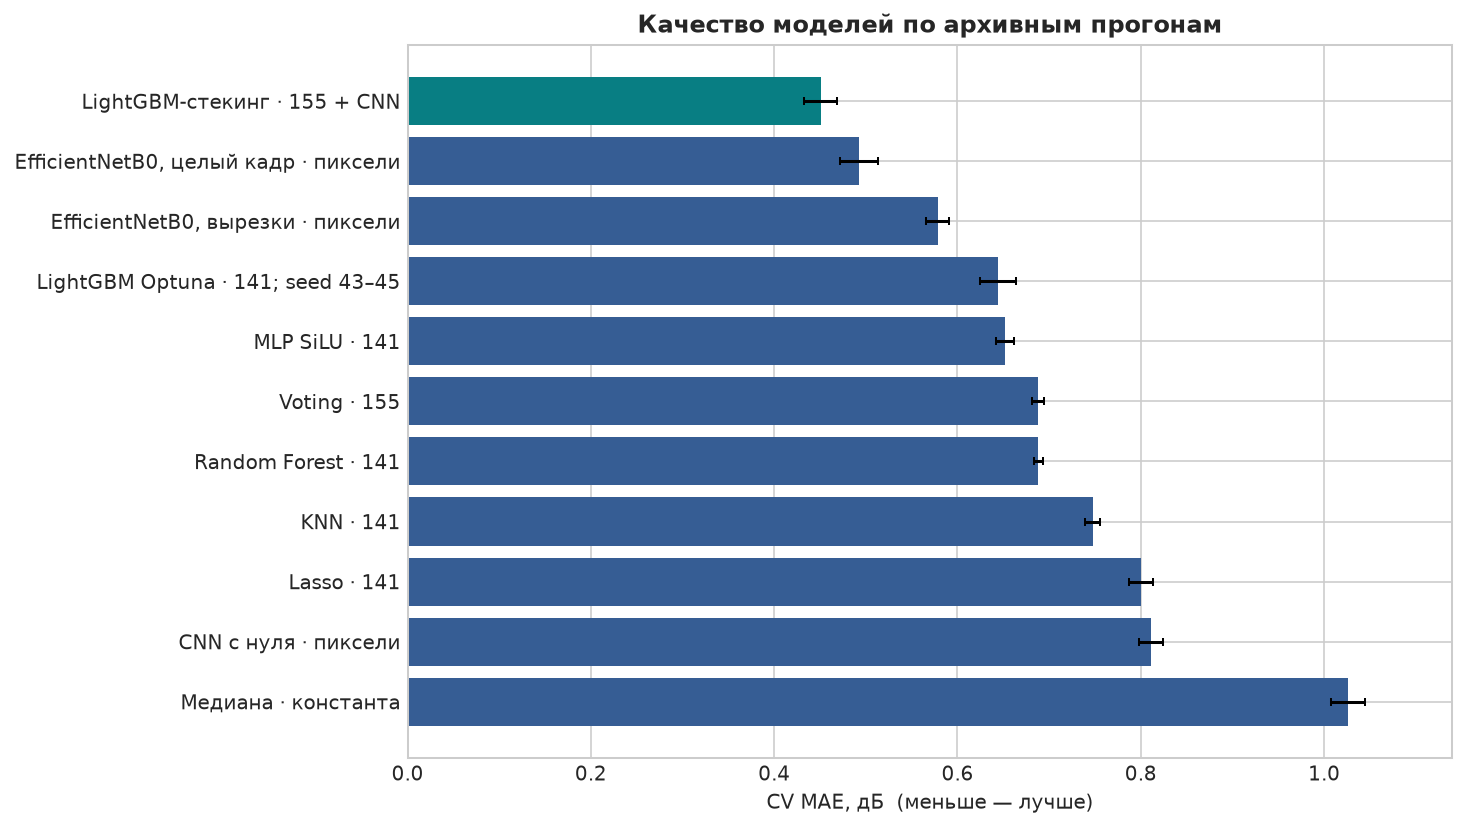

In [2]:
series = [
    ("Медиана", "01-baseline/results_main.csv", "median", "константа"),
    ("Lasso", "04-preprocessing/results_main.csv", "lasso ", "141"),
    ("KNN", "05-knn-tree-forest/results_main.csv", "knn ", "141"),
    ("Random Forest", "05-knn-tree-forest/results_main.csv", "forest ", "141"),
    ("LightGBM Optuna", "07-tuning/results_tuning.csv", "lightgbm tuned", "141; seed 43–45"),
    ("MLP SiLU", "08-mlp/results_mlp.csv", "mlp_combined activation=silu dropout=0.2", "141"),
    ("CNN с нуля", "09-cnn/results_cnn_small.csv", "cnn_small", "пиксели"),
    ("EfficientNetB0, вырезки", "09-cnn/results_efficientnet_crop.csv", "cnn_efficientnet_crop", "пиксели"),
    ("EfficientNetB0, целый кадр", "09-cnn/results_efficientnet.csv", "cnn_efficientnet", "пиксели"),
    ("Voting", "14-voting/results.csv", "voting", "155"),
    ("LightGBM-стекинг", "11-features/results_ensemble.csv", "stacking_predictions", "155 + CNN"),
]
rows = []
for label, file, prefix, inputs in series:
    table = read(file)
    row = table[table.model.str.startswith(prefix)].sort_values("mae").iloc[0]
    rows.append(dict(model=label, inputs=inputs, mae=row.mae, fold_std=row.fold_std, source=file))
summary = pd.DataFrame(rows).sort_values("mae", ascending=False)
summary.to_csv(output / "model_summary.csv", index=False)
display(summary.sort_values("mae").round(6))

fig, ax = plt.subplots(figsize=(10, 5.6), layout="constrained")
labels = summary.model + " · " + summary.inputs
ax.barh(labels, summary.mae, xerr=summary.fold_std,
        color=[teal if name == "LightGBM-стекинг" else blue for name in summary.model], capsize=2)
ax.set(xlabel="CV MAE, дБ  (меньше — лучше)", title="Качество моделей по архивным прогонам", xlim=(0, 1.14))
publish(fig, "01_models.png")

## Как параметры влияли на качество

На графиках показаны попарно сопоставимые серии. Для дерева фиксирован минимальный размер листа 5, для KNN показаны комбинации двух расстояний и двух схем весов. Кривые Optuna показывают лучший результат на разбиении поиска к данному испытанию. Для MLP сопоставляются выбранные конфигурации, а не значения loss по эпохам.

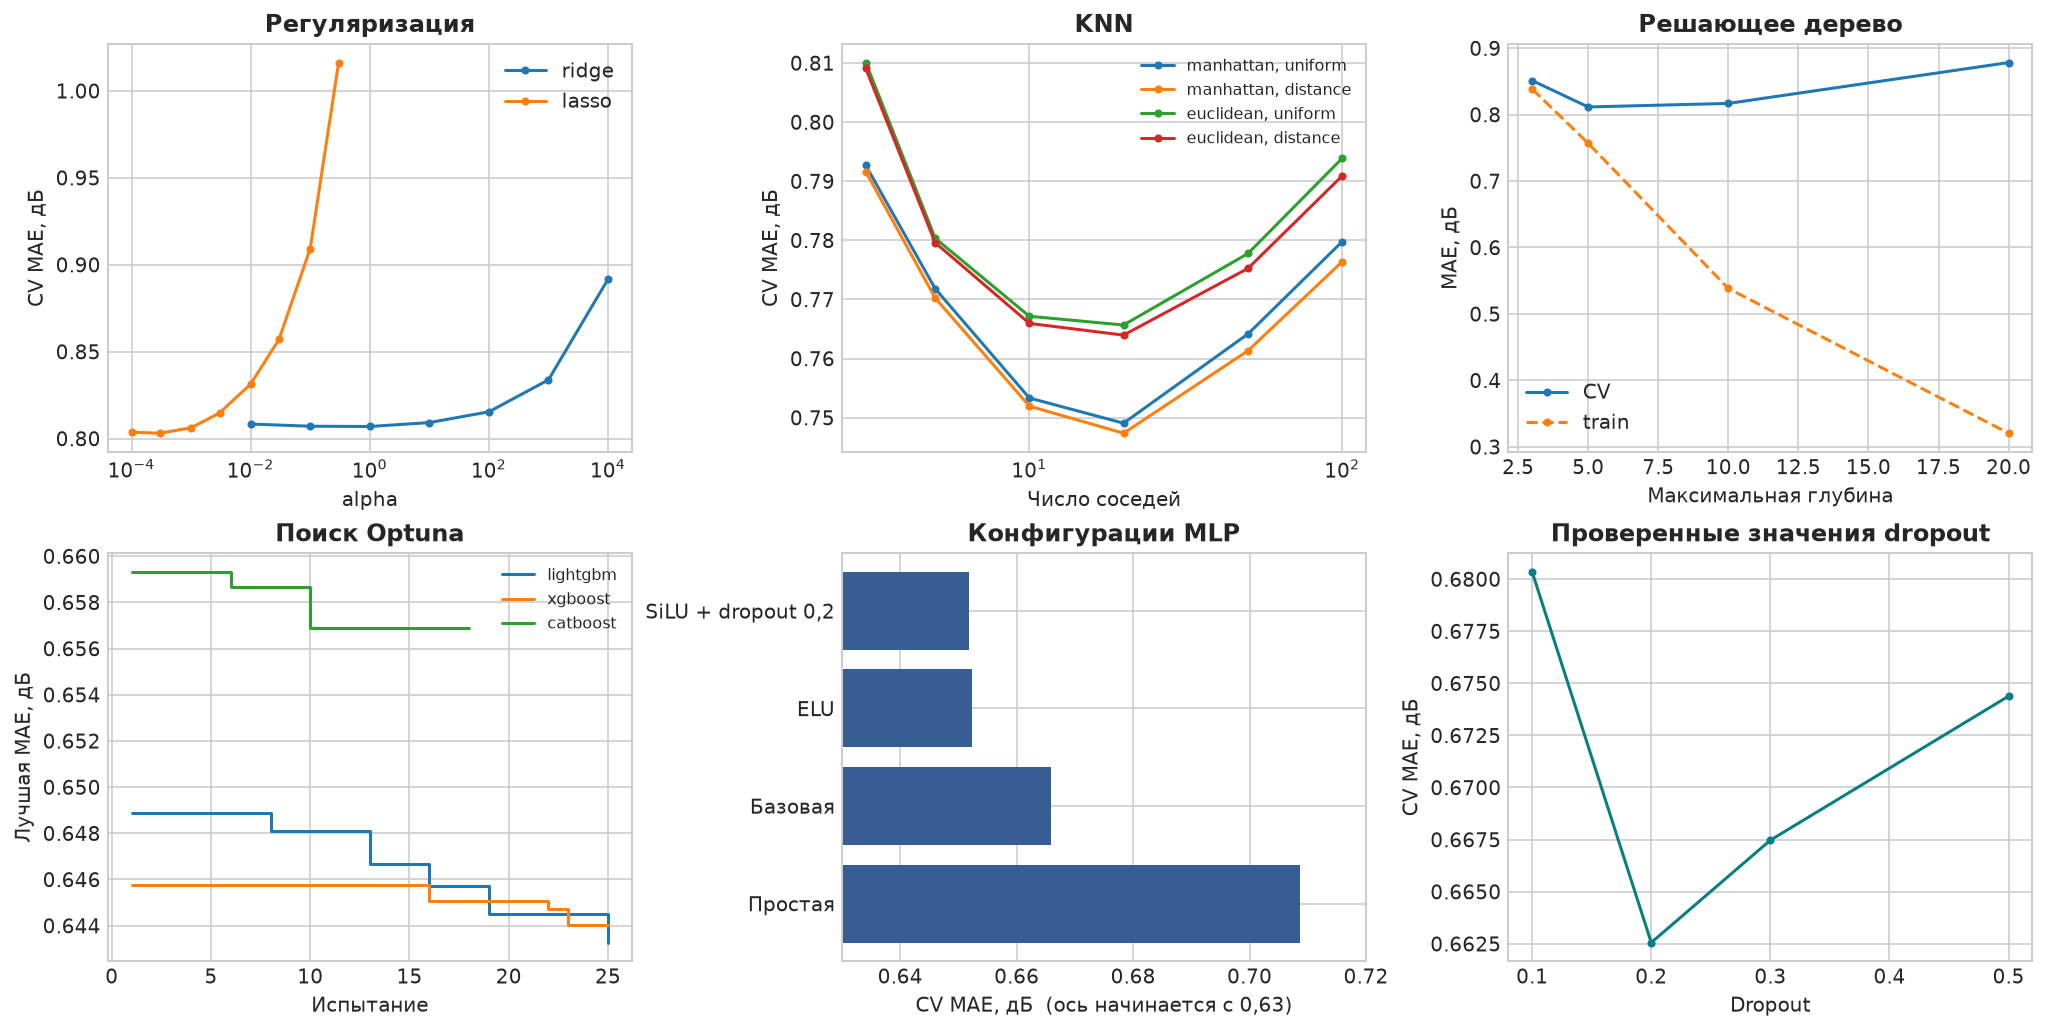

In [3]:
linear = read("03-linear-models/results_main.csv")
classic = read("05-knn-tree-forest/results_main.csv")
fig, axes = plt.subplots(2, 3, figsize=(14, 7), layout="constrained")
ax = axes[0, 0]
for name in ("ridge", "lasso"):
    rows = linear[linear.model.str.startswith(name + " ")].copy()
    rows["alpha"] = rows.model.str.extract(r"alpha=([^ ]+)")[0].astype(float)
    rows = rows.sort_values("alpha")
    ax.plot(rows.alpha, rows.mae, ".-", label=name)
ax.set(xscale="log", xlabel="alpha", ylabel="CV MAE, дБ", title="Регуляризация")
ax.legend()

ax = axes[0, 1]
for metric in ("manhattan", "euclidean"):
    for weight in ("uniform", "distance"):
        rows = classic[classic.model.str.startswith(f"knn metric={metric} ") &
                       classic.model.str.endswith(f"weights={weight}")].copy()
        rows["k"] = rows.model.str.extract(r"n_neighbors=(\d+)")[0].astype(int)
        rows = rows.sort_values("k")
        ax.plot(rows.k, rows.mae, ".-", label=f"{metric}, {weight}")
ax.set(xscale="log", xlabel="Число соседей", ylabel="CV MAE, дБ", title="KNN")
ax.legend(fontsize=8)

ax = axes[0, 2]
tree = classic[classic.model.str.match(r"tree max_depth=\d+ min_samples_leaf=5$")].copy()
tree["depth"] = tree.model.str.extract(r"max_depth=(\d+)")[0].astype(int)
tree = tree.sort_values("depth")
ax.plot(tree.depth, tree.mae, ".-", label="CV")
ax.plot(tree.depth, tree.train_mae, ".--", label="train")
ax.set(xlabel="Максимальная глубина", ylabel="MAE, дБ", title="Решающее дерево")
ax.legend()

ax = axes[1, 0]
for name in ("lightgbm", "xgboost", "catboost"):
    trials = read(f"07-tuning/trials_{name}.csv").query("state == 'COMPLETE'").sort_values("number")
    assert not trials.empty
    ax.step(trials.number + 1, trials.value.cummin(), where="post", label=name)
ax.set(xlabel="Испытание", ylabel="Лучшая MAE, дБ", title="Поиск Optuna")
ax.legend(fontsize=8)

mlp = read("08-mlp/results_mlp.csv").set_index("model").mae
choices = {"Простая": "mlp_simple", "Базовая": "mlp_base",
           "ELU": "mlp_activation activation=elu", "SiLU + dropout 0,2": "mlp_combined activation=silu dropout=0.2"}
ax = axes[1, 1]
ax.barh(list(choices), mlp[list(choices.values())], color=blue)
ax.set(xlim=(0.63, 0.72), xlabel="CV MAE, дБ  (ось начинается с 0,63)", title="Конфигурации MLP")

ax = axes[1, 2]
drop = mlp[mlp.index.str.startswith("mlp_dropout ")].rename(index=lambda x: float(x.split("=")[1])).sort_index()
ax.plot(drop.index, drop.values, ".-", color=teal)
ax.set(xlabel="Dropout", ylabel="CV MAE, дБ", title="Проверенные значения dropout")
publish(fig, "02_parameters.png")

## Признаки и ансамбли

Добавление 14 признаков искажений дало основной набор из 155 признаков. Для дополнительных 12 комбинаций используем парный контроль прогона 12. Отрицательная разность означает уменьшение ошибки. Сравнение стекеров на готовых OOF здесь не является полной вложенной CV. Оценки Kaggle приведены только для фактически отправленных файлов.

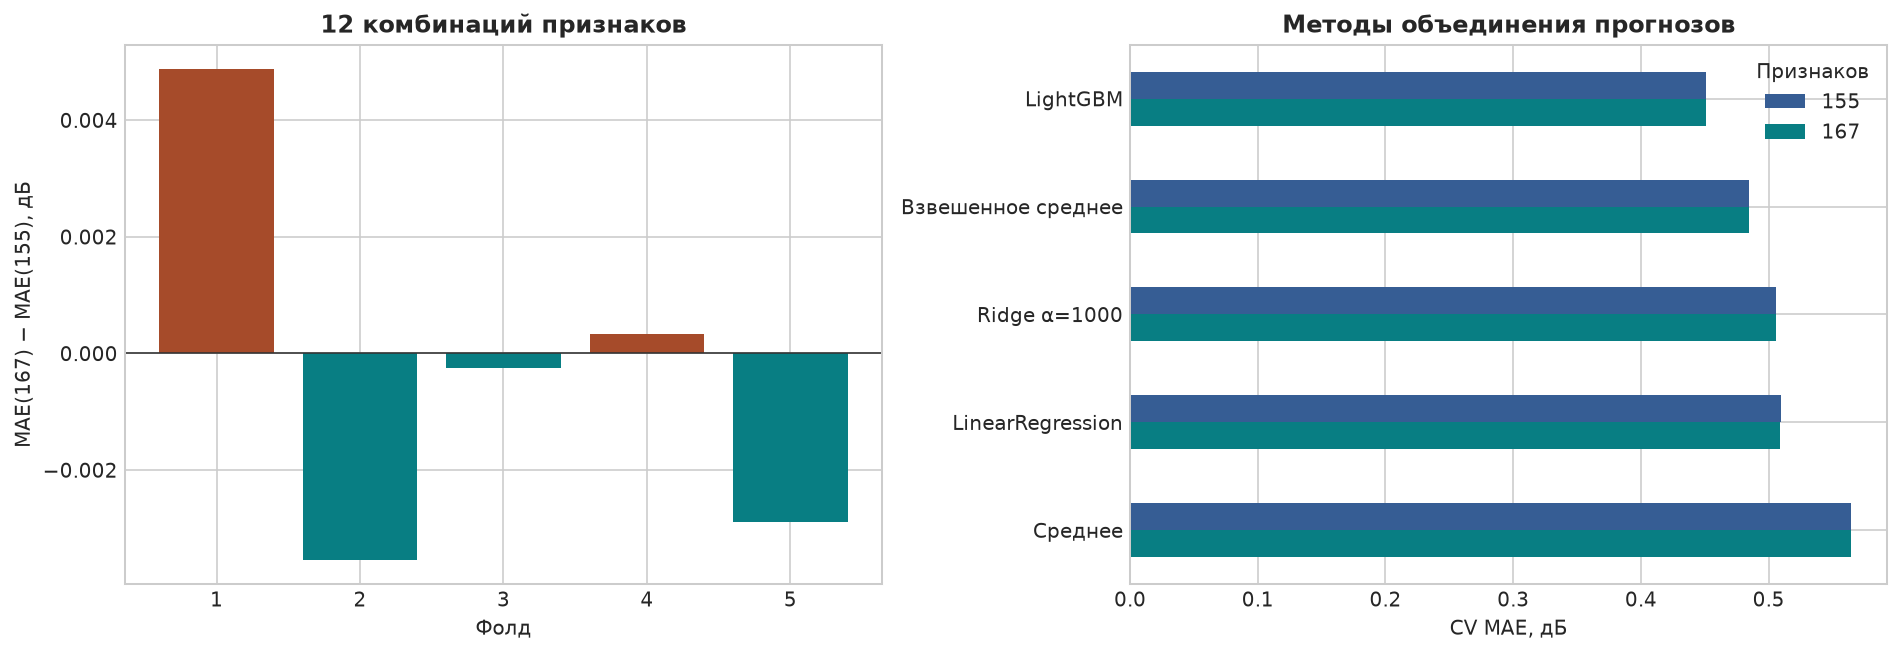

,model,ref,public,private
0,"LightGBM, 155",58445233,0.41641,0.41627
1,"Ridge, 155",58462179,0.46667,0.47736
2,"Ridge, 167",58462231,0.46523,0.47504


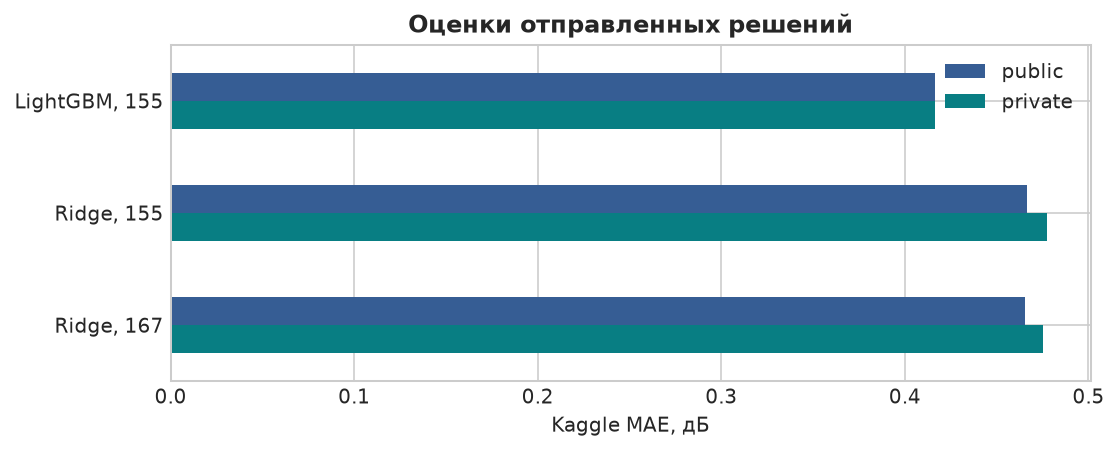

In [4]:
paired = read("12-combinations/fold_comparison.csv")
delta = paired.query("stage == 'ensemble' and model == 'stacking_predictions'").sort_values("fold")
assert len(delta) == 5
np.testing.assert_allclose(delta.combinations - delta.baseline, delta.delta, atol=1e-12)
ensembles = read("13-linear-ensemble/comparison.csv")
names = {"mean": "Среднее", "weights": "Взвешенное среднее", "stacking_linear": "LinearRegression",
         "stacking_ridge alpha=1000.0": "Ridge α=1000", "stacking_predictions": "LightGBM"}
compare = ensembles[ensembles.model.isin(names)].pivot(index="model", columns="features", values="mae")
compare = compare.rename(index=names).sort_values(155)
compare.to_csv(output / "ensemble_comparison.csv")

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
a.bar(delta.fold, delta.delta, color=[teal if value < 0 else orange for value in delta.delta])
a.axhline(0, color="#333333", linewidth=0.8)
a.set(xlabel="Фолд", ylabel="MAE(167) − MAE(155), дБ", title="12 комбинаций признаков", xticks=delta.fold)
compare.plot.barh(ax=b, color=[blue, teal])
b.invert_yaxis()
b.set(xlabel="CV MAE, дБ", ylabel="", title="Методы объединения прогнозов")
b.legend(title="Признаков")
publish(fig, "03_ensembles.png")

best = json.loads((root / "runs/11-features/submission_result.json").read_text(encoding="utf-8"))
ridge = json.loads((root / "runs/13-linear-ensemble/submissions/manifest.json").read_text(encoding="utf-8"))
scores = pd.DataFrame([{"model": label, "ref": entry.get("submission_ref", entry.get("ref")),
                        "public": float(entry["public_score"]), "private": float(entry["private_score"])}
                       for label, entry in zip(["LightGBM, 155", "Ridge, 155", "Ridge, 167"], [best, *ridge], strict=True)])
scores.to_csv(output / "kaggle_scores.csv", index=False)
display(scores)
fig, ax = plt.subplots(figsize=(7.6, 3), layout="constrained")
scores.set_index("model")[["public", "private"]].plot.barh(ax=ax, color=[blue, teal])
ax.invert_yaxis()
ax.set(xlabel="Kaggle MAE, дБ", ylabel="", title="Оценки отправленных решений")
publish(fig, "04_kaggle.png")

## Где ошибается выбранный ансамбль

Остаток рассчитан как прогноз минус факт. На графиках используются OOF-прогнозы прогона 11. Суффиксы вариантов применяются только для анализа. Для `_5` поздний анализ указывает на изменение размера с восстановлением. MAE по диапазонам PSNR дополняется числом изображений, поскольку правый хвост редок.

,group,mae,n,grouping
0,_1,0.632679,2642,Вариант искажения
1,_2,0.088016,2642,Вариант искажения
2,_3,0.323344,2642,Вариант искажения
3,_4,0.613802,2642,Вариант искажения
4,_5,0.596094,2642,Вариант искажения
5,до 28,0.260000,5863,"Фактический PSNR, дБ"
6,28–30,0.342292,4951,"Фактический PSNR, дБ"
7,30–35,0.836830,2247,"Фактический PSNR, дБ"
8,35–40,4.026476,114,"Фактический PSNR, дБ"
9,выше 40,11.327290,35,"Фактический PSNR, дБ"


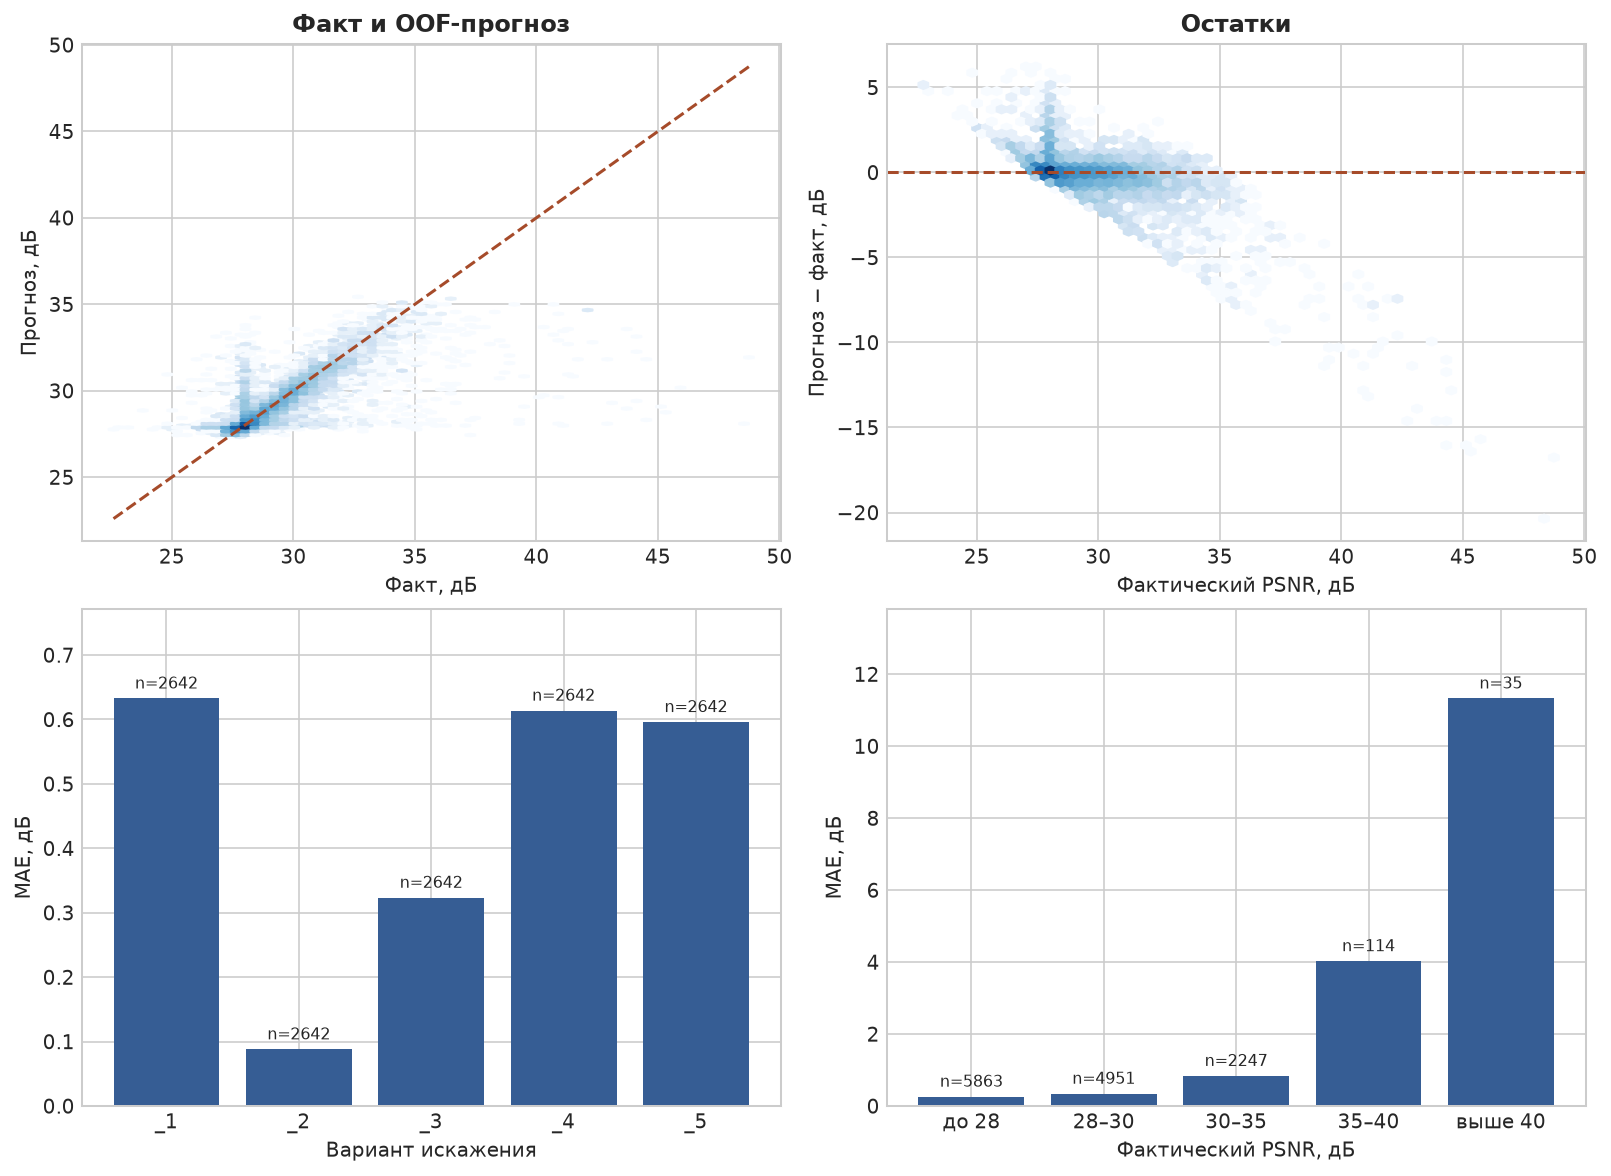

In [5]:
oof = read("11-features/oof_ensemble.csv")
assert len(oof) == 13210 and oof.img_name.is_unique
oof["residual"] = oof.stacking_predictions - oof.PSNR
oof["abs_error"] = oof.residual.abs()
expected = read("11-features/results_ensemble.csv").set_index("model").loc["stacking_predictions", "mae"]
np.testing.assert_allclose(oof.abs_error.mean(), expected, rtol=0, atol=1e-12)
bins = pd.cut(oof.PSNR, [-np.inf, 28, 30, 35, 40, np.inf],
              labels=["до 28", "28–30", "30–35", "35–40", "выше 40"])
groups = [
    ("Вариант искажения", oof.img_name.str.extract(r"(_\d+)\.png$")[0]),
    ("Фактический PSNR, дБ", bins),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
ax = axes[0, 0]
ax.hexbin(oof.PSNR, oof.stacking_predictions, gridsize=65, mincnt=1, bins="log", cmap="Blues")
limits = [oof[["PSNR", "stacking_predictions"]].min().min(), oof[["PSNR", "stacking_predictions"]].max().max()]
ax.plot(limits, limits, "--", color=orange)
ax.set(xlabel="Факт, дБ", ylabel="Прогноз, дБ", title="Факт и OOF-прогноз")
ax = axes[0, 1]
ax.hexbin(oof.PSNR, oof.residual, gridsize=65, mincnt=1, bins="log", cmap="Blues")
ax.axhline(0, linestyle="--", color=orange)
ax.set(xlabel="Фактический PSNR, дБ", ylabel="Прогноз − факт, дБ", title="Остатки")
error_tables = []
for ax, (label, group) in zip(axes[1], groups):
    assert group.notna().all()
    stats = oof.groupby(group, observed=True).agg(mae=("abs_error", "mean"), n=("abs_error", "size"))
    bar = ax.bar([str(v) for v in stats.index], stats.mae, color=blue)
    ax.bar_label(bar, labels=[f"n={n}" for n in stats.n], padding=3, fontsize=8)
    ax.set(xlabel=label, ylabel="MAE, дБ", ylim=(0, stats.mae.max() * 1.22))
    error_tables.append(stats.rename_axis("group").reset_index().assign(grouping=label))
errors = pd.concat(error_tables, ignore_index=True)
errors.to_csv(output / "error_breakdown.csv", index=False)
display(errors.round(6))
publish(fig, "05_errors.png")

## Файл сабмита

Для выбранного решения берём столбец `stacking_predictions` из архива прогона 11. Сохраняем точное текстовое представление прогноза и порядок исходных строк. Создание файла не отправляет результат в соревнование.

In [6]:
test = pd.read_csv(root / "runs/11-features/test_ensemble.csv", dtype=str)
reference = read("11-features/test_base.csv")
submission = test[["img_name", "stacking_predictions"]].rename(columns={"stacking_predictions": "PSNR"})
assert len(submission) == 3310 and submission.img_name.is_unique
assert submission.img_name.equals(reference.img_name)
assert np.isfinite(pd.to_numeric(submission.PSNR)).all()
submission_path = output / "submission.csv"
submission.to_csv(submission_path, index=False, lineterminator="\n")
digest = hashlib.sha256(submission_path.read_bytes()).hexdigest()
assert digest == best["sha256"], "CSV отличается от отправленного сабмита"
display(submission.head())
print(f"Сохранён submission.csv, {len(submission)} строк. SHA-256 совпадает с архивным сабмитом.")

,img_name,PSNR
0,100090_1.png,29.871996958732154
1,100090_2.png,27.87651805775879
2,100090_3.png,27.86559470239453
3,100090_4.png,27.953728062320533
4,100090_5.png,30.772712092756954


Сохранён submission.csv, 3310 строк. SHA-256 совпадает с архивным сабмитом.


## Выводы

- Среди показанных моделей на пикселях лучший результат дала EfficientNetB0 на целом кадре (MAE 0,493 на CV). Выбранный стекер объединяет её с другими прогнозами и даёт 0,451 на CV.
- В паре 155 → 167 LightGBM-стекинг выиграл на трёх фолдах из пяти. Малый средний выигрыш не даёт оснований заменить набор из 155 признаков.
- В проверенных сабмитах Ridge уступил LightGBM-стекингу на обеих частях теста. Voting совпал с равным средним своих участников и уступил лучшему участнику.
- На отложенных прогнозах редкие высокие PSNR труднее предсказывать. При сравнении ошибок по хвосту важно учитывать размер каждой группы.